Import the libraries and set the dataset path relative to this notebook.

In [15]:
import pandas as pd
import numpy as np
from pathlib import Path

DATA_DIR = Path("../data/UCI HAR Dataset")

Read the activity labels into a dictionary keyed by activity number.

In [16]:
activity_labels = pd.read_csv(DATA_DIR / "activity_labels.txt", sep=r"\s+", header=None)
activity_names = dict(zip(activity_labels[0], activity_labels[1]))

Load the feature, activity, and subject files for both data splits.

In [17]:
X_train = pd.read_csv(DATA_DIR / "train/X_train.txt", sep=r"\s+", header=None)
y_train = pd.read_csv(DATA_DIR / "train/y_train.txt", sep=r"\s+", header=None)
subject_train = pd.read_csv(DATA_DIR / "train/subject_train.txt", sep=r"\s+", header=None)

X_test = pd.read_csv(DATA_DIR / "test/X_test.txt", sep=r"\s+", header=None)
y_test = pd.read_csv(DATA_DIR / "test/y_test.txt", sep=r"\s+", header=None)
subject_test = pd.read_csv(DATA_DIR / "test/subject_test.txt", sep=r"\s+", header=None)

Print the number of rows and features in each split.

In [18]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (7352, 561)
X_test shape: (2947, 561)


Compare activity counts by name across the train and test splits.

In [19]:
activity_counts = pd.DataFrame({
    "train": y_train[0].map(activity_names).value_counts(),
    "test": y_test[0].map(activity_names).value_counts(),
}).rename_axis("activity")
print(activity_counts.to_string())

                    train  test
activity                       
LAYING               1407   537
SITTING              1286   491
STANDING             1374   532
WALKING              1226   496
WALKING_DOWNSTAIRS    986   420
WALKING_UPSTAIRS     1073   471


Count unique subjects and check whether the two splits share any subjects.

In [20]:
train_subjects = set(subject_train[0])
test_subjects = set(subject_test[0])
print("Unique train subjects:", len(train_subjects))
print("Unique test subjects:", len(test_subjects))
print("No subjects in both splits:", train_subjects.isdisjoint(test_subjects))

Unique train subjects: 21
Unique test subjects: 9
No subjects in both splits: True


Raw sensor signals are in `Inertial Signals/`. Each row is one 2.56-second window of 128 readings sampled at 50 Hz.

In [21]:
signal_dir = DATA_DIR / "train/Inertial Signals"
total_acc_x_train = pd.read_csv(signal_dir / "total_acc_x_train.txt", sep=r"\s+", header=None)
total_acc_y_train = pd.read_csv(signal_dir / "total_acc_y_train.txt", sep=r"\s+", header=None)
total_acc_z_train = pd.read_csv(signal_dir / "total_acc_z_train.txt", sep=r"\s+", header=None)

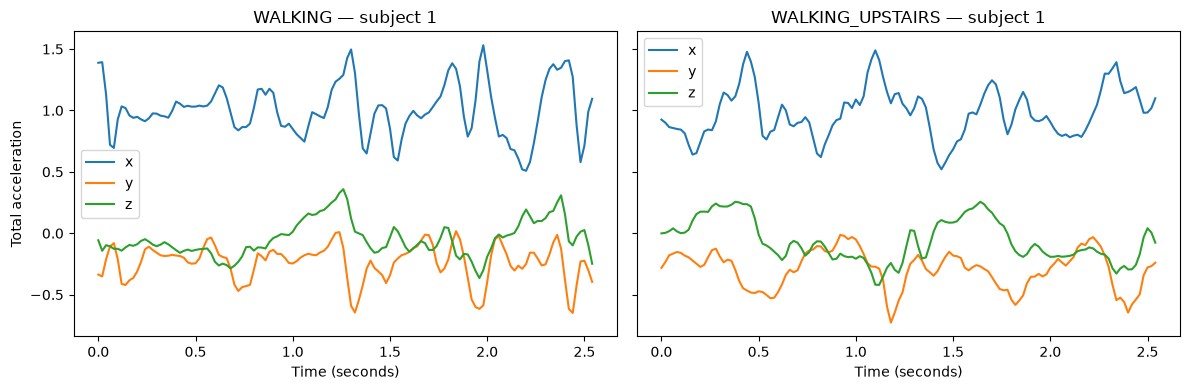

In [22]:
import matplotlib.pyplot as plt

walking_id = next(number for number, name in activity_names.items() if name == "WALKING")
upstairs_id = next(number for number, name in activity_names.items() if name == "WALKING_UPSTAIRS")
walking_subjects = set(subject_train.loc[y_train[0] == walking_id, 0])
upstairs_subjects = set(subject_train.loc[y_train[0] == upstairs_id, 0])
subject = min(walking_subjects & upstairs_subjects)

fig, axes = plt.subplots(1, 2, sharey=True, figsize=(12, 4))
for ax, activity_id in zip(axes, (walking_id, upstairs_id)):
    window_index = subject_train.index[(subject_train[0] == subject) & (y_train[0] == activity_id)][0]
    seconds = np.arange(total_acc_x_train.shape[1]) / 50
    for axis_name, signal in (("x", total_acc_x_train), ("y", total_acc_y_train), ("z", total_acc_z_train)):
        ax.plot(seconds, signal.iloc[window_index].to_numpy(), label=axis_name)
    ax.set_title(f"{activity_names[activity_id]} — subject {subject}")
    ax.set_xlabel("Time (seconds)")
    ax.legend()
axes[0].set_ylabel("Total acceleration")
fig.tight_layout()
plt.show()

**Similar:** Both show a regular step rhythm (~1 peak every 0.5–0.6 s), and x stays near 1 g because total acceleration includes gravity.

**Different:** Walking has sharper, taller x-spikes from heel strikes; stair climbing is smoother with lower peaks and more drift in z, likely from leaning forward.

**Takeaway:** These are hard to tell apart by eye — a good setup for a “guess the activity” exhibit and for explaining the model’s mistakes.